# 01 – Panel quality check (έλεγχος ποιότητας δείγματος)

**Project:** Consumer panel weighting & projection – dunnhumby *The Complete Journey*

**Ερώτηση:** Είναι αντιπροσωπευτικό το panel των νοικοκυριών; Πριν κάνουμε στάθμιση (weighting), ελέγχουμε:
1. την ποιότητα των ωμών δεδομένων (κενά, διπλές γραμμές, μηδενικές/αρνητικές αξίες),
2. την «υγεία» του panel ανά εβδομάδα (πόσα νοικοκυριά αγοράζουν),
3. ποια νοικοκυριά είναι **static panel** (αγοράζουν σταθερά όλη την περίοδο), γιατί μόνο αυτά προβάλλονται,
4. πόσα έχουν δημογραφικά και αν διαφέρουν από τα υπόλοιπα,
5. πόσο απέχει το δείγμα από τον πληθυσμό (US Census, ACS 2012) **πριν** τη στάθμιση.

Τρέξε τα κελιά με τη σειρά (Shift+Enter).

In [3]:
import os
os.chdir(r'C:\Projects\circana-panel-weighting')
print(os.getcwd())
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RAW, CLEAN, IMG, TARGETS = 'data-raw', 'data-clean', 'images', 'data-targets'
for folder in [CLEAN, IMG]:
    os.makedirs(folder, exist_ok=True)

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
print('OK')

C:\Projects\circana-panel-weighting
OK


## 1. Φόρτωση δεδομένων
Τρία αρχεία: `transaction_data.csv` (1 γραμμή = 1 προϊόν σε ένα καλάθι), `hh_demographic.csv` (δημογραφικά ανά νοικοκυριό), `product.csv` (κατηγορία κάθε προϊόντος).
Τα ονόματα των στηλών τα κάνουμε πεζά για να γράφουμε πιο εύκολα SQL αργότερα.

In [4]:
trans = pd.read_csv(f'{RAW}/transaction_data.csv')
demo = pd.read_csv(f'{RAW}/hh_demographic.csv')
prod = pd.read_csv(f'{RAW}/product.csv')
for df in (trans, demo, prod):
    df.columns = df.columns.str.strip().str.lower()

print('transactions:', trans.shape)
print('demographics:', demo.shape)
print('products    :', prod.shape)
trans.head()

transactions: (2595732, 12)
demographics: (801, 8)
products    : (92353, 7)


,household_key,basket_id,day,product_id,quantity,sales_value,store_id,retail_disc,trans_time,week_no,coupon_disc,coupon_match_disc
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


## 2. Profiling: τι έχουμε στα χέρια μας
Πόσα νοικοκυριά, ποιο χρονικό εύρος, κενά (nulls) και διπλές γραμμές.

In [5]:
print('Households in transactions :', trans['household_key'].nunique())
print('Households with demographics:', demo['household_key'].nunique())
print('Demographic households not in transactions:',
      len(set(demo['household_key']) - set(trans['household_key'])))
print('Weeks:', trans['week_no'].min(), '-', trans['week_no'].max(),
      '| Days:', trans['day'].min(), '-', trans['day'].max())
print('Stores:', trans['store_id'].nunique(), '| Baskets:', trans['basket_id'].nunique())
print()
print('Nulls per column (transactions):')
print(trans.isna().sum()[trans.isna().sum() > 0] if trans.isna().sum().sum() else 'none')
print('Nulls per column (demographics):')
print(demo.isna().sum()[demo.isna().sum() > 0] if demo.isna().sum().sum() else 'none')

Households in transactions : 2500
Households with demographics: 801
Demographic households not in transactions: 0
Weeks: 1 - 102 | Days: 1 - 711
Stores: 582 | Baskets: 276484

Nulls per column (transactions):
none
Nulls per column (demographics):
none


## 3. Έλεγχοι ποιότητας (data quality checks)
Κάθε έλεγχος μετράει πόσες γραμμές έχουν πρόβλημα. Τα αποτελέσματα σώζονται στο `data-clean/quality_checks.csv` (όπως ένα log ποιότητας σε παραγωγή).

In [6]:
checks = {
    'Exact duplicate rows': trans.duplicated().sum(),
    'Sales value = 0': (trans['sales_value'] == 0).sum(),
    'Sales value < 0': (trans['sales_value'] < 0).sum(),
    'Quantity = 0': (trans['quantity'] == 0).sum(),
    'Product not in product table': (~trans['product_id'].isin(prod['product_id'])).sum(),
    'Duplicate household in demographics': demo['household_key'].duplicated().sum(),
}
qc = pd.DataFrame({'check': list(checks), 'rows': list(checks.values())})
qc['pct_of_rows'] = (qc['rows'] / len(trans) * 100).round(3)
qc.to_csv(f'{CLEAN}/quality_checks.csv', index=False)
qc

,check,rows,pct_of_rows
0,Exact duplicate rows,0,0.000
1,Sales value = 0,18850,0.726
2,Sales value < 0,0,0.000
3,Quantity = 0,14466,0.557
4,Product not in product table,0,0.000
5,Duplicate household in demographics,0,0.000


**Απόφαση καθαρισμού:** κρατάμε μόνο γραμμές με `sales_value > 0`, γιατί μια αγορά χωρίς αξία δεν μετράει στις πωλήσεις. Τις γραμμές με `quantity = 0` τις κρατάμε (έχουν αξία), αλλά τις αναφέρουμε. Αν υπάρχουν ακριβώς διπλές γραμμές, τις αφαιρούμε.
Μετά προσθέτουμε το τμήμα (department) κάθε προϊόντος.

In [7]:
before = len(trans)
trans = trans.drop_duplicates()
trans = trans[trans['sales_value'] > 0].copy()
trans = trans.merge(prod[['product_id', 'department', 'commodity_desc']], on='product_id', how='left')
print(f'Rows before: {before:,} | after: {len(trans):,} | removed: {before - len(trans):,}')

Rows before: 2,595,732 | after: 2,576,882 | removed: 18,850


## 4. Υγεία του panel ανά εβδομάδα
Σε ένα σωστό panel ο αριθμός των νοικοκυριών που αγοράζουν κάθε εβδομάδα είναι σχετικά σταθερός. Πτώσεις ή «ράμπα» στην αρχή σημαίνουν ότι το panel δεν είναι ακόμα σταθερό ή ότι λείπουν δεδομένα.

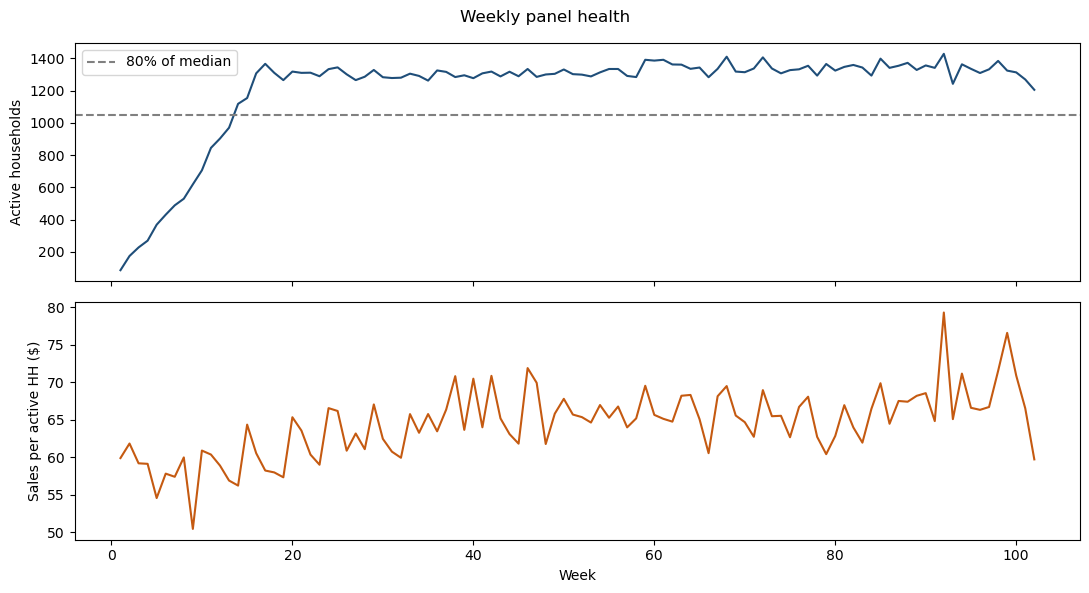

Median active households per week: 1310.5
Weeks below 80% of median: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


In [8]:
weekly = (trans.groupby('week_no')
               .agg(active_households=('household_key', 'nunique'),
                    baskets=('basket_id', 'nunique'),
                    sales=('sales_value', 'sum'))
               .reset_index())
weekly['sales_per_active_hh'] = weekly['sales'] / weekly['active_households']
median_active = weekly['active_households'].median()
weekly['low_week_flag'] = weekly['active_households'] < 0.8 * median_active

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(weekly['week_no'], weekly['active_households'], color='#1f4e79')
ax[0].axhline(0.8 * median_active, ls='--', color='grey', label='80% of median')
ax[0].set_ylabel('Active households'); ax[0].legend()
ax[1].plot(weekly['week_no'], weekly['sales_per_active_hh'], color='#c55a11')
ax[1].set_ylabel('Sales per active HH ($)'); ax[1].set_xlabel('Week')
fig.suptitle('Weekly panel health')
plt.tight_layout(); plt.savefig(f'{IMG}/weekly_panel_health.png', dpi=120); plt.show()

print('Median active households per week:', median_active)
print('Weeks below 80% of median:', weekly.loc[weekly['low_week_flag'], 'week_no'].tolist())

## 5. Περίοδος ανάλυσης και static panel
Για την προβολή θέλουμε **ένα πλήρες έτος**: κρατάμε τις τελευταίες 52 εβδομάδες (51–102), που είναι μακριά από την αρχή των δεδομένων.
Τις χωρίζουμε σε 13 περιόδους των 4 εβδομάδων (όπως τα «4-week periods» της αγοράς FMCG).

**Static panel** = νοικοκυριό που αγόρασε σε τουλάχιστον `MIN_PERIODS` από τις 13 περιόδους. Αυτά είναι τα «αξιόπιστα» νοικοκυριά: αν κάποιος αγοράζει σπάνια, δεν ξέρουμε αν έφυγε από το panel ή απλώς ψώνισε αλλού.
Ο πίνακας ευαισθησίας δείχνει πόσα νοικοκυριά μένουν για κάθε όριο, ώστε η επιλογή να είναι τεκμηριωμένη.

In [9]:
WEEK_START, WEEK_END = 51, 102
MIN_PERIODS = 12

win = trans[trans['week_no'].between(WEEK_START, WEEK_END)].copy()
win['period'] = (win['week_no'] - WEEK_START) // 4 + 1          # 1..13

hh = (win.groupby('household_key')
         .agg(periods_active=('period', 'nunique'),
              weeks_active=('week_no', 'nunique'),
              baskets=('basket_id', 'nunique'),
              annual_spend=('sales_value', 'sum'))
         .reset_index())

sensitivity = pd.DataFrame({'min_periods': range(8, 14)})
sensitivity['households'] = [(hh['periods_active'] >= k).sum() for k in sensitivity['min_periods']]
sensitivity['pct_of_active'] = (sensitivity['households'] / len(hh) * 100).round(1)
print('Households active in the 52 weeks:', len(hh))
sensitivity

Households active in the 52 weeks: 2479


,min_periods,households,pct_of_active
0,8,2031,81.9
1,9,1908,77.0
2,10,1788,72.1
3,11,1613,65.1
4,12,1406,56.7
5,13,1107,44.7


In [10]:
hh['static'] = hh['periods_active'] >= MIN_PERIODS
print(f"Static panel (>= {MIN_PERIODS} of 13 periods): {hh['static'].sum()} households "
      f"({hh['static'].mean()*100:.1f}%)")
print(hh.groupby('static')[['annual_spend', 'baskets']].median().round(1))

Static panel (>= 12 of 13 periods): 1406 households (56.7%)
        annual_spend  baskets
static                       
False          446.7     17.0
True          2222.7     73.0


## 6. Ακραίες τιμές (outliers) στη δαπάνη
Με τον κανόνα IQR: ακραίο = πάνω από Q3 + 3×IQR. Δεν τα σβήνουμε (μπορεί να είναι μεγάλες οικογένειες ή μικρές επιχειρήσεις), αλλά τα σημαδεύουμε, γιατί στη στάθμιση ένα ακραίο νοικοκυριό με μεγάλο βάρος επηρεάζει πολύ τα αποτελέσματα.

In [11]:
static_hh = hh[hh['static']].copy()
q1, q3 = static_hh['annual_spend'].quantile([0.25, 0.75])
upper = q3 + 3 * (q3 - q1)
static_hh['spend_outlier'] = static_hh['annual_spend'] > upper
print(static_hh['annual_spend'].describe().round(1))
print(f'Upper fence (Q3 + 3*IQR): {upper:,.0f} $ | outliers: {static_hh["spend_outlier"].sum()}')
hh = hh.merge(static_hh[['household_key', 'spend_outlier']], on='household_key', how='left')
hh['spend_outlier'] = hh['spend_outlier'].fillna(False).astype(bool)

count     1406.0
mean      2800.2
std       2202.7
min        169.9
25%       1278.1
50%       2222.7
75%       3667.6
max      26529.7
Name: annual_spend, dtype: float64
Upper fence (Q3 + 3*IQR): 10,836 $ | outliers: 9


C:\Users\zozo\AppData\Local\Temp\ipykernel_30480\471206679.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hh['spend_outlier'] = hh['spend_outlier'].fillna(False).astype(bool)


## 7. Κάλυψη δημογραφικών: είναι τα νοικοκυριά με δημογραφικά «ίδια» με τα υπόλοιπα;
Μπορούμε να σταθμίσουμε **μόνο** όσα έχουν δημογραφικά. Αν αυτά ξοδεύουν διαφορετικά από τα υπόλοιπα, έχουμε **non-response bias** (μεροληψία μη απόκρισης).
Χρησιμοποιούμε το **Mann-Whitney U test** (μη παραμετρικό, γιατί η δαπάνη είναι λοξή κατανομή και όχι κανονική).

In [12]:
hh['has_demo'] = hh['household_key'].isin(demo['household_key'])
s = hh[hh['static']]
print(f"Static households with demographics: {s['has_demo'].sum()} of {len(s)} ({s['has_demo'].mean()*100:.1f}%)")
print(s.groupby('has_demo')[['annual_spend', 'baskets', 'periods_active']].median().round(1))

u, p = stats.mannwhitneyu(s.loc[s['has_demo'], 'annual_spend'],
                          s.loc[~s['has_demo'], 'annual_spend'], alternative='two-sided')
print(f'Mann-Whitney U on annual spend: U={u:,.0f}, p={p:.4f}')

Static households with demographics: 730 of 1406 (51.9%)
          annual_spend  baskets  periods_active
has_demo                                       
False           1529.7     57.0            13.0
True            2868.9     84.5            13.0
Mann-Whitney U on annual spend: U=355,462, p=0.0000


## 8. Δείγμα vs πληθυσμός (πριν τη στάθμιση)
Στόχοι: νοικοκυριά ΗΠΑ από το **American Community Survey 2012** (πίνακες B25007 ηλικία υπευθύνου, B19001 εισόδημα, B11016 μέγεθος), αρχείο `data-targets/us_household_targets_acs2012.csv`.
Ενώνουμε τις μικρές κατηγορίες εισοδήματος του dunnhumby ώστε να ταιριάζουν με το Census (150–199K και 200K+).
Ο **chi-square goodness-of-fit** ελέγχει αν το δείγμα διαφέρει σημαντικά από τον πληθυσμό.

In [13]:
income_map = {'150-174K': '150-199K', '175-199K': '150-199K', '200-249K': '200K+', '250K+': '200K+'}
demo['age'] = demo['age_desc']
demo['income'] = demo['income_desc'].replace(income_map)
demo['hh_size'] = demo['household_size_desc'].astype(str)

targets = pd.read_csv(f'{TARGETS}/us_household_targets_acs2012.csv')
sample = demo.merge(hh.loc[hh['static'], ['household_key']], on='household_key')
print('Static households with demographics (sample for weighting):', len(sample))

rows = []
for var in ['age', 'income', 'hh_size']:
    t = targets[targets['variable'] == var].set_index('category')['households']
    t = t / t.sum() * 100
    n = sample[var].value_counts().reindex(t.index, fill_value=0)
    chi, p = stats.chisquare(n, f_exp=t / 100 * n.sum())
    for cat in t.index:
        rows.append([var, cat, n[cat], round(n[cat] / n.sum() * 100, 1), round(t[cat], 1),
                     round(n[cat] / n.sum() * 100 - t[cat], 1)])
    print(f'{var:8s} chi-square = {chi:7.1f}, p = {p:.2e}')

compare = pd.DataFrame(rows, columns=['variable', 'category', 'n_sample', 'sample_pct', 'census_pct', 'diff_pp'])
compare

Static households with demographics (sample for weighting): 730
age      chi-square =   232.0, p = 4.07e-48
income   chi-square =    99.6, p = 1.87e-17
hh_size  chi-square =    37.4, p = 1.48e-07


,variable,category,n_sample,sample_pct,census_pct,diff_pp
0,age,19-24,39,5.3,4.0,1.3
1,age,25-34,133,18.2,15.3,2.9
2,age,35-44,179,24.5,18.0,6.5
3,age,45-54,266,36.4,20.8,15.6
4,age,55-64,55,7.5,19.0,-11.5
5,age,65+,58,7.9,22.9,-14.9
6,income,Under 15K,52,7.1,13.3,-6.2
7,income,15-24K,68,9.3,11.1,-1.8
8,income,25-34K,69,9.5,10.4,-0.9
9,income,35-49K,161,22.1,13.8,8.3


## 9. Αποθήκευση για τα επόμενα βήματα
- `data-clean/households.csv`: ένα νοικοκυριό ανά γραμμή (δραστηριότητα, static, δημογραφικά).
- `data-clean/panel.db` (SQLite) με πίνακες `households`, `products`, `transactions` (μόνο οι 52 εβδομάδες), για τα SQL queries στο DBeaver.
- `data-clean/sample_vs_census.csv`: ο πίνακας της ενότητας 8.

In [14]:
households = hh.merge(demo[['household_key', 'age', 'income', 'hh_size']], on='household_key', how='left')
households.to_csv(f'{CLEAN}/households.csv', index=False)
compare.to_csv(f'{CLEAN}/sample_vs_census.csv', index=False)

cols = ['household_key', 'basket_id', 'day', 'week_no', 'period', 'product_id', 'quantity',
        'sales_value', 'store_id', 'department', 'commodity_desc']
db_path = f'{CLEAN}/panel.db'
if os.path.exists(db_path):
    os.remove(db_path)
with sqlite3.connect(db_path) as con:
    households.to_sql('households', con, index=False)
    prod.to_sql('products', con, index=False)
    win[cols].to_sql('transactions', con, index=False, chunksize=100_000)
    for table in ['households', 'products', 'transactions']:
        print(table, pd.read_sql(f'SELECT COUNT(*) AS n FROM {table}', con)['n'][0])

households 2479
products 92353
transactions 1455605
